## Individuell uppgift – Hälsostudie

  **Del 1** – Grundläggande analys och statistik
 
  **Del 2** – Fördjupning och pipeline

### Del 1 – Grundläggande analys och statistik
  - Beskrivande analys
  - Simulering
  - Konfidensintervall
  - Hypotesprövning
  - Powersimulering
  - Motivering av metodval (Del 1)
  - Slutsats (Del 1)

In [1]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)

In [2]:
from src.health_functions import(
    descriptive_stats,
    simulate_disease_share,
    ci_mean_normal,
    ci_mean_bootstrap,
    welch_ttest,
    estimate_power_by_simulation,
    fit_linear_regression,
)

#### Beskrivande analys

In [3]:
## Läsa i data

df = pd.read_csv("data/health_study_dataset.csv")
df.head()


,id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
0,1,57,F,168.9,65.8,141.8,4.58,No,0
1,2,47,M,180.4,95.9,144.8,5.18,Yes,0
2,3,59,F,169.9,82.2,151.7,6.16,No,0
3,4,72,M,157.7,93.1,151.0,6.63,No,0
4,5,46,M,192.6,104.1,144.1,5.21,No,0


In [4]:
## Kolla om datan behöver rensas

df.info()


<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           800 non-null    int64  
 1   age          800 non-null    int64  
 2   sex          800 non-null    str    
 3   height       800 non-null    float64
 4   weight       800 non-null    float64
 5   systolic_bp  800 non-null    float64
 6   cholesterol  800 non-null    float64
 7   smoker       800 non-null    str    
 8   disease      800 non-null    int64  
dtypes: float64(4), int64(3), str(2)
memory usage: 56.4 KB


In [5]:
## Räkna värden i de kategoriska kolumnerna

print(df.isna().sum())
print(df["sex"].value_counts())
print(df["smoker"].value_counts())
print(df["disease"].value_counts())

id             0
age            0
sex            0
height         0
weight         0
systolic_bp    0
cholesterol    0
smoker         0
disease        0
dtype: int64
sex
F    403
M    397
Name: count, dtype: int64
smoker
No     587
Yes    213
Name: count, dtype: int64
disease
0    753
1     47
Name: count, dtype: int64


##### Översikt av datan

Datasetet innehåller 800 deltagare och 9 kolumner. Det finns inga saknade värden, så ingen datarensning behövs. Kolumnerna sex och smoker är kategoriska (text). Kolumnen disease lagras som siffror (0/1) men är också kategorisk: 1 betyder att personen har sjukdomen. Kolumnen id är bara ett löpnummer och används inte i analysen. Övriga kolumner är numeriska.

In [6]:
## Beskrivande analys för age, weight, height, systolic_bp, cholesterol

cols = ["age","weight","height","systolic_bp","cholesterol"]
summary = descriptive_stats(df, cols)
summary


,age,weight,height,systolic_bp,cholesterol
mean,49.43,73.41,171.85,149.18,4.93
median,50.00,73.20,171.35,149.40,4.97
min,18.00,33.70,144.40,106.80,2.50
max,90.00,114.40,200.40,185.90,7.88


##### Tolkning av beskrivande statistik

Medelvärde och median ligger mycket nära varandra för alla variabler, till exempel 149,2 och 149,4 mmHg för blodtryck. Det tyder på att fördelningarna är ungefär symmetriska utan stora extremvärden som drar medelvärdet åt ett håll.

Deltagarna är mellan 18 och 90 år, med en medelålder på cirka 49 år. Längd och vikt ligger inom rimliga intervall, men den lägsta vikten (33,7 kg) är ovanligt låg för en vuxen och kan vara ett extremvärde.

Medelvärdet för systoliskt blodtryck är cirka 149 mmHg, vilket är över den vanliga gränsen för högt blodtryck (cirka 140 mmHg). Deltagarna har alltså i genomsnitt förhöjt blodtryck. 

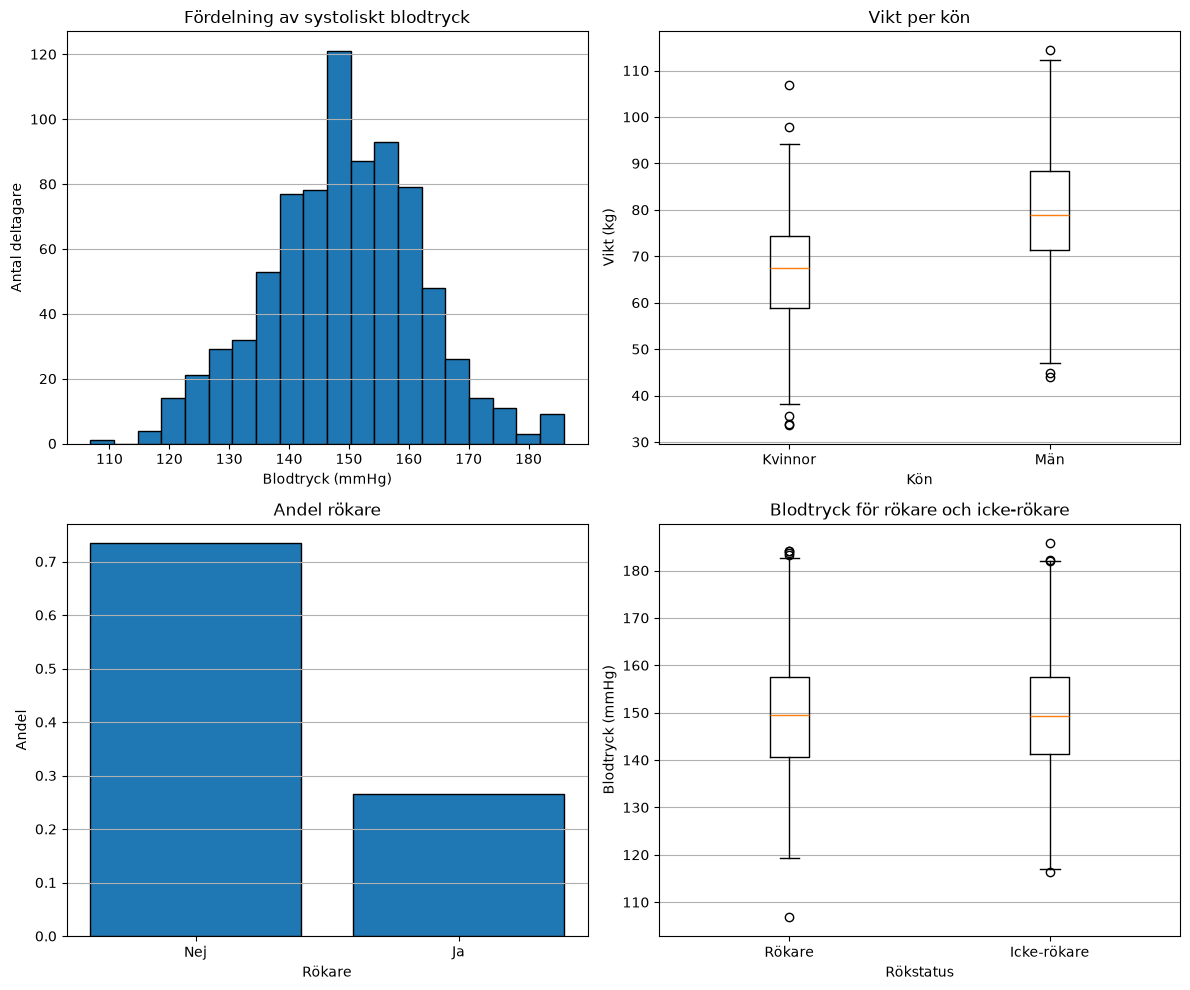

In [7]:
## Visualisering av datan

fig, axes = plt.subplots(2, 2, figsize = (12,10), sharex=False, sharey = False)

## Histogram över blodtryck

axes[0,0].hist(df["systolic_bp"], bins = 20, edgecolor = "black")
axes[0,0].set_title("Fördelning av systoliskt blodtryck")
axes[0,0].set_xlabel("Blodtryck (mmHg)")
axes[0,0].set_ylabel("Antal deltagare")
axes[0,0].grid(True, axis="y")

## Boxplot över vikt per kön

axes[0,1].boxplot([df.loc[df["sex"] == "F", "weight"], df.loc[df["sex"] == "M", "weight"]], tick_labels=["Kvinnor", "Män"])
axes[0,1].set_title("Vikt per kön")
axes[0,1].set_xlabel("Kön")
axes[0,1].set_ylabel("Vikt (kg)")
axes[0,1].grid(True, axis = "y")

## Stapeldiagram över andelen rökare

smoker_share = df["smoker"].value_counts(normalize=True).rename({"No":"Nej", "Yes":"Ja"})
axes[1,0].bar(smoker_share.index, smoker_share.values, edgecolor="black")
axes[1,0].set_title("Andel rökare")
axes[1,0].set_xlabel("Rökare")
axes[1,0].set_ylabel("Andel")
axes[1,0].grid(True, axis="y")

## Boxplot över blodtryck för rökare och icke-rökare

axes[1,1].boxplot([df.loc[df["smoker"] == "Yes", "systolic_bp"], df.loc[df["smoker"] == "No","systolic_bp"]], tick_labels = ["Rökare","Icke-rökare"])
axes[1,1].set_title("Blodtryck för rökare och icke-rökare")
axes[1,1].set_xlabel("Rökstatus")
axes[1,1].set_ylabel("Blodtryck (mmHg)")              
axes[1,1].grid(True, axis = "y")

plt.tight_layout()
plt.show()


##### Tolkning av graferna

**Histogram:** Blodtrycket är ungefär normalfördelat, med de flesta deltagarna kring 145–155 mmHg. Det stämmer med att medelvärde och median ligger nära varandra.

**Vikt per kön:** Män väger i genomsnitt mer än kvinnor (median cirka 79 kg mot 67 kg). Båda grupperna har några extremvärden, bland annat den låga vikten på 33,7 kg.

**Andel rökare:** Cirka 27 % av deltagarna röker och 73 % röker inte. Grupperna är alltså olika stora.

**Blodtryck för rökare och icke-rökare:** Boxplottarna är nästan identiska, med median kring 149–150 mmHg i båda grupperna. Det finns ingen tydlig skillnad i grafen, men det undersöks närmare med en hypotesprövning senare.

#### Simulering kopplad till caset

In [8]:
## Simulering av sjukdomsandel
## Skillnaden mellan simulerad och verklig andel
## Räkna ut standardfelet

p_disease = df["disease"].mean()
p_sim, se_sim = simulate_disease_share(p_disease, 1000,rng)

print(f"Verklig andel: {p_disease:.4f}")
print(f"Simulerad andel: {p_sim:.4f}")
print(f"Differens: {p_sim - p_disease:.4f}")
print(f"Förväntat standardfel: {se_sim:.4f}")

Verklig andel: 0.0587
Simulerad andel: 0.0650
Differens: 0.0063
Förväntat standardfel: 0.0074


##### Tolkning av simuleringen

Den verkliga andelen deltagare med sjukdomen är 0,0587, alltså cirka 5,9 %. I simuleringen av 1000 personer blev andelen 0,065, alltså 6,5 %. Skillnaden mellan den simulerade och den verkliga andelen är bara 0,0063.

Skillnaden är mindre än det förväntade standardfelet (0,0074), vilket betyder att den ligger inom normal slumpvariation. Andelarna blir inte exakt lika eftersom varje simulerad person får sjukdomen slumpmässigt, med sannolikheten 0,0587. Med fler simulerade personer, till exempel 100 000 istället för 1000, skulle skillnaden bli ännu mindre.

#### Konfidensintervall

In [9]:
## Konfidensintervall för medelvärdet av systolic_bp - med normalapproximation 

bp = df["systolic_bp"]
lo, hi, mean_bp, sd_bp, n = ci_mean_normal(bp)

print(f"Medelvärde:{mean_bp:.2f} mmHg")
print(f"Standardavvikelse:{sd_bp:.2f} mmHg")
print(f"n = {n}")
print(f"95% KI(normalapprox.):{lo:.2f} -{hi: .2f} mmHg")

Medelvärde:149.18 mmHg
Standardavvikelse:12.79 mmHg
n = 800
95% KI(normalapprox.):148.29 - 150.07 mmHg


##### Tolkning av konfidensintervallet

Medelvärdet för systoliskt blodtryck är 149,18 mmHg. Vi är 95 % säkra på att det sanna medelvärdet för systoliskt blodtryck i populationen ligger mellan 148,29 och 150,07 mmHg.

Intervallet är smalt eftersom stickprovet är stort (n = 800). Standardfelet (sd / √n) blir mindre när stickprovet blir större.

Jag använder 95 % konfidensnivå eftersom det är standard inom forskning och motsvarar signifikansnivån α = 0,05 som används i hypotesprövningen.

In [10]:
## Konfidensintervall för medelvärdet av systolic_bp - med bootstrapmetoden.

blo, bhi, bmean, boot_means = ci_mean_bootstrap(bp, rng)

print(f"95% KI (bootstrap): {blo:.2f}-{bhi:.2f} mmHg")
print(f"95% KI (normalapprox): {lo:.2f}-{hi:.2f} mmHg")

95% KI (bootstrap): 148.31-150.07 mmHg
95% KI (normalapprox): 148.29-150.07 mmHg


##### Jämförelse av metoderna

Båda metoderna ger samma övre gräns, 150,07 mmHg, medan den nedre gränsen bara skiljer sig med 0,02 mmHg (148,29 mot 148,31 mmHg). Metoderna ger alltså i praktiken samma resultat.

Normalapproximationen bygger på en formel och antar att stickprovsmedelvärdet är normalfördelat. Bootstrap gör inget sådant antagande, utan drar istället 10 000 nya stickprov med återläggning från datan och använder fördelningen av deras medelvärden.

Att metoderna ger nästan samma intervall visar att normalapproximationens antagande håller här. Det beror på att stickprovet är stort (n = 800), så att centrala gränsvärdessatsen gäller, och att blodtrycket är ungefär symmetriskt fördelat, vilket syns i histogrammet.

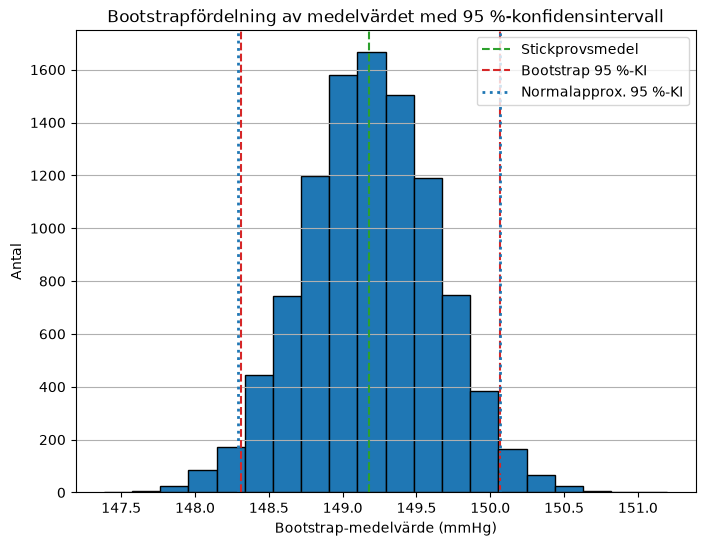

In [11]:
fig, ax = plt.subplots(figsize = (8,6))

ax.hist(boot_means, bins = 20, edgecolor = "black")
ax.axvline(bmean, color = "tab:green", linestyle = "--", label = "Stickprovsmedel")
ax.axvline(blo, color="tab:red", linestyle="--", label="Bootstrap 95 %-KI")
ax.axvline(bhi, color="tab:red", linestyle="--")
ax.axvline(lo, color="tab:blue", linestyle=":", linewidth=2, label="Normalapprox. 95 %-KI")
ax.axvline(hi, color="tab:blue", linestyle=":", linewidth=2)
ax.set_title("Bootstrapfördelning av medelvärdet med 95 %-konfidensintervall")
ax.set_xlabel("Bootstrap-medelvärde (mmHg)")
ax.set_ylabel("Antal")
ax.grid(True, axis="y")
ax.legend()

plt.show()

##### Tolkning av grafen

Histogrammet visar fördelningen av de 10 000 bootstrap-medelvärdena. Fördelningen är klockformad, vilket visar att medelvärdet är ungefär normalfördelat, precis som centrala gränsvärdessatsen säger.

De röda och blå linjerna visar 95 %-konfidensintervallet beräknat med bootstrapmetoden respektive normalapproximationen. Linjerna ligger nästan exakt på varandra, vilket visar att metoderna ger nästan samma intervall och att normalapproximationens antagande håller här.

#### Hypotesprövning

Påstående: "Rökare har högre medelblodtryck än icke-rökare."

- H₀: Rökare har inte högre medelblodtryck än icke-rökare.
- H₁: Rökare har högre medelblodtryck än icke-rökare.
- Signifikansnivå: α = 0,05

- Testet är ensidigt eftersom påståendet gäller "högre", inte bara "olika".
- Jag använder Welchs t-test eftersom grupperna är olika stora (213 och 587) och testet inte förutsätter lika varians.

In [12]:
## Hypotesprövning:har rökare högre blodtryck än icke - rökare?

smokers = df.loc[df["smoker"] == "Yes", "systolic_bp"]
non_smokers = df.loc[df["smoker"] == "No", "systolic_bp"]

t_stat, p_value = welch_ttest(smokers, non_smokers)

print(f"Medelvärde rökare:{smokers.mean():.2f} mmHg (n={len(smokers)})")
print(f"Medelvärde icke-rökare:{non_smokers.mean():.2f} mmHg (n={len(non_smokers)})")
print(f"Skillnad: {smokers.mean() - non_smokers.mean():.2f} mmHg")
print(f"t = {t_stat:.3f}")
print(f"p-värde = {p_value:.4f}")

Medelvärde rökare:149.52 mmHg (n=213)
Medelvärde icke-rökare:149.05 mmHg (n=587)
Skillnad: 0.47 mmHg
t = 0.450
p-värde = 0.3264


##### Tolkning av hypotesprövningen

Medelvärdet för rökare är 149,52 mmHg och för icke-rökare 149,05 mmHg. Rökarna har alltså 0,47 mmHg högre medelblodtryck i stickprovet.

P-värdet är 0,3264, vilket är större än signifikansnivån α = 0,05. Därför kan vi inte förkasta H₀. Datan ger alltså inte stöd för påståendet att rökare har högre medelblodtryck än icke-rökare.

Det betyder inte att det inte finns någon skillnad, utan att datan inte är tillräckligt stark för att visa en skillnad. Skillnaden på 0,47 mmHg är så liten att den lätt kan bero på slumpvariation. Det stämmer med boxplotten, där blodtrycket för rökare och icke-rökare ser nästan likadant ut.

#### Powersimulering

In [13]:
## Powersimulering: hur bra är testet på att hitta en skillnad?

n1, n2 = len(smokers), len(non_smokers)
diffs_to_try = [0, 0.5, 1, 2, 3, 4, 5]

sim_power = [estimate_power_by_simulation(n1, n2, d, sd_bp, mean_bp, rng)
            for d in diffs_to_try]

power_df = pd.DataFrame({"Verklig_skillnad_mmHg": diffs_to_try,
                         "simulerad_power":sim_power})
power_df


,Verklig_skillnad_mmHg,simulerad_power
0,0.0,0.0610
1,0.5,0.1310
2,1.0,0.2535
3,2.0,0.6385
4,3.0,0.9130
5,4.0,0.9875
6,5.0,0.9985


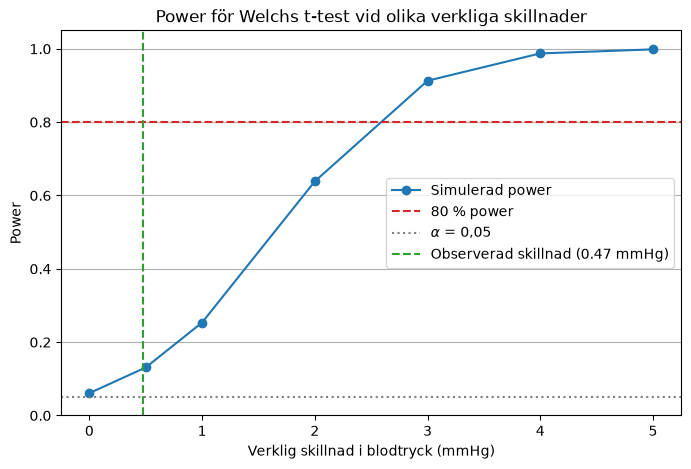

In [14]:
## Visualisering av powersimuleringen

obs_diff = smokers.mean() - non_smokers.mean()

fig, ax = plt.subplots(figsize = (8, 5))

ax.plot(diffs_to_try, sim_power, marker = "o", label = "Simulerad power")
ax.axhline(0.8, color="tab:red", linestyle="--", label="80 % power")
ax.axhline(0.05, color="tab:gray", linestyle=":", label=r"$\alpha$ = 0,05")
ax.axvline(obs_diff, color = "tab:green", linestyle="--", label=f"Observerad skillnad ({obs_diff:.2f} mmHg)")
ax.set_title("Power för Welchs t-test vid olika verkliga skillnader")
ax.set_xlabel("Verklig skillnad i blodtryck (mmHg)")
ax.set_ylabel("Power")
ax.set_ylim(0, 1.05)
ax.grid(True, axis="y")
ax.legend()

plt.show()


##### Tolkning av powersimuleringen

**Power** betyder hur ofta testet hittar en skillnad när det verkligen finns en skillnad.

Jag simulerade 2000 studier för varje skillnad mellan 0 och 5 mmHg. Jag använde samma medelvärde, standardavvikelse och gruppstorlekar som i datasetet.

**Resultat:**

- Ju större skillnaden är, desto högre blir power.
- Vid 3 mmHg eller mer hittar testet skillnaden i över 90 % av fallen.
- Vid 0 mmHg är power cirka 0,05. Det är rätt, eftersom testet ger ett falskt larm i 5 % av fallen (α = 0,05).

**Vad betyder det?**

Skillnaden i min data är bara 0,47 mmHg. Vid en så liten skillnad hittar testet den bara i cirka 13 % av fallen. Därför är det inte konstigt att hypotesprövningen inte gav ett signifikant resultat. Skillnaden är för liten för att upptäckas med 800 personer.

#### Motivering av metodval (Del 1)

**Simulering med seed**
Jag använder `np.random.default_rng(42)` för alla slumpmässiga beräkningar. Med en seed blir resultaten samma varje gång notebooken körs, så att analysen går att upprepa.
Källa: [NumPy – Random Generator](https://numpy.org/doc/stable/reference/random/generator.html)

**Konfidensintervall: normalapproximation**
Normalapproximationen är enkel och fungerar bra när stickprovet är stort. Enligt centrala gränsvärdessatsen är medelvärdet då ungefär normalfördelat, även om datan inte är perfekt normalfördelad. Med n = 800 är det uppfyllt.

**Konfidensintervall: bootstrap**
Bootstrap bygger inte på något antagande om fördelningen. Därför använder jag den som en kontroll av normalapproximationen. Båda metoderna gav nästan samma intervall, vilket visar att resultatet är pålitligt.
Källa: Efron, B. & Tibshirani, R. J. (1993). *An Introduction to the Bootstrap*. Chapman & Hall.
Källa: [NumPy – Generator.choice](https://numpy.org/doc/stable/reference/random/generated/numpy.random.Generator.choice.html)

**Hypotesprövning: Welchs t-test**
Jag jämför medelvärden, eftersom blodtryck är en numerisk variabel. Jag väljer Welchs t-test (`equal_var=False`) eftersom grupperna är olika stora (213 och 587) och testet inte kräver att grupperna har samma varians. Testet är ensidigt (`alternative="greater"`) eftersom hypotesen gäller att rökare har *högre* blodtryck.
Källa: [SciPy – scipy.stats.ttest_ind](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html)

**Powersimulering**
Jag simulerar blodtryck med en normalfördelning, eftersom histogrammet visar att blodtrycket är ungefär normalfördelat. De simulerade studierna använder datasetets medelvärde, standardavvikelse och gruppstorlekar, så att de liknar den verkliga studien. Gränsen 80 % power är en vanlig tumregel för när ett test anses tillräckligt bra.
Källa: [NumPy – Generator.normal](https://numpy.org/doc/stable/reference/random/generated/numpy.random.Generator.normal.html)
Källa: Cohen, J. (1988). *Statistical Power Analysis for the Behavioral Sciences* (2nd ed.). Lawrence Erlbaum.

#### Slutsats (Del 1)

- Deltagarna har i genomsnitt förhöjt blodtryck (cirka 149 mmHg). Medelvärde och median ligger nära varandra för alla variabler.
- Andelen med sjukdomen är cirka 5,9 %. Simuleringen av 1000 personer gav 6,5 %, och skillnaden beror på slumpvariation.
- Det sanna medelvärdet för blodtryck ligger med 95 % säkerhet mellan cirka 148,3 och 150,1 mmHg. Normalapproximation och bootstrap gav nästan samma intervall.
- Rökare har bara 0,47 mmHg högre blodtryck än icke-rökare, och skillnaden är inte signifikant (p = 0,33).
- Powersimuleringen visar att testet bara hittar en så liten skillnad i cirka 13 % av fallen. Testet är pålitligt först vid skillnader på cirka 3 mmHg eller mer.

### Del 2 – Fördjupning och pipeline       
  - Klassen HealthAnalyzer                    
  - Linjär regression                         
  - Ny analys och visualisering             
  - Multipel regression                     
  - Motivering av metodval (Del 2)          
  - Slutsats (Del 2)                        

#### Klassen HealthAnalyzer

Klassen `HealthAnalyzer` samlar datan och flera analysmetoder i ett objekt. Datan sparas en gång när objektet skapas, och sedan kan olika analyser göras med metoder utan att datan behöver skickas in varje gång.

In [15]:
from src.health_analyzer import HealthAnalyzer

analyzer = HealthAnalyzer(df)
print(analyzer)
analyzer.summary(["age","systolic_bp","cholesterol"])

HealthAnalyzer(n_deltagare=800, kolumner = ['id', 'age', 'sex', 'height', 'weight', 'systolic_bp', 'cholesterol', 'smoker', 'disease'])


,age,systolic_bp,cholesterol
mean,49.43,149.18,4.93
median,50.00,149.40,4.97
min,18.00,106.80,2.50
max,90.00,185.90,7.88


In [16]:
# Samma hypotesprövning som i Del 1, nu med klassen

result = analyzer.compare_groups("systolic_bp", "smoker", "Yes", "No")
result

{'medel_grupp1': np.float64(149.524882629108),
 'medel_grupp2': np.float64(149.05298126064736),
 'skillnad': np.float64(0.47190136846063524),
 't': 0.4503433193393224,
 'p': 0.32636693716994986}

In [17]:
# Klassen kan återanvändas för en ny fråga: skiljer sig blodtrycket mellan män och kvinnor

result_sex = analyzer.compare_groups("systolic_bp", "sex", "M", "F", alternative="two-sided")
result_sex

{'medel_grupp1': np.float64(150.24307304785893),
 'medel_grupp2': np.float64(148.13002481389577),
 'skillnad': np.float64(2.1130482339631556),
 't': 2.3434984045304,
 'p': 0.01934911819808673}

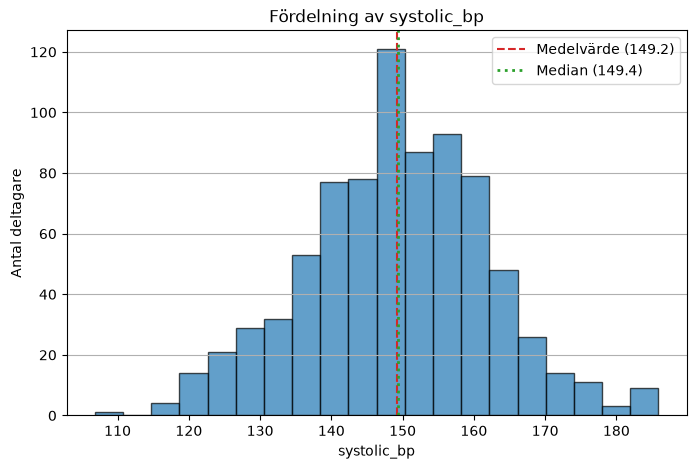

In [18]:
analyzer.plot_histogram("systolic_bp")
plt.show()

##### Tolkning av klassens resultat

Klassen ger samma resultat som i Del 1 för rökare och icke-rökare (skillnad 0,47 mmHg, p = 0,33). Det visar att klassen fungerar korrekt.

Klassen kan också användas för nya frågor. Män har i genomsnitt 150,24 mmHg och kvinnor 148,13 mmHg, alltså 2,11 mmHg högre hos män. Testet är tvåsidigt eftersom vi inte hade någon hypotes i förväg om vilken grupp som har högre blodtryck. P-värdet är 0,019, vilket är mindre än 0,05. Skillnaden mellan män och kvinnor är alltså statistiskt signifikant.

Histogrammet visar att medelvärdet och medianen nästan sammanfaller, vilket stämmer med att blodtrycket är ungefär symmetriskt fördelat.

#### Linjär regression: blodtryck och ålder

Jag använder linjär regression för att undersöka hur blodtrycket förändras med åldern. Modellen skrivs i matrisform som y = X · β och löses med minsta kvadratmetoden i numpy (`np.linalg.lstsq`).

In [19]:
coefs, r2, y_pred = fit_linear_regression(df, ["age"], "systolic_bp")

print(f"Intercept (b₀) : {coefs['intercept']:.2f} mmHg")
print(f"Lutning (b₁) : {coefs['age']:.3f} mmHg per år")
print(f"R² : {r2:.3f}")

Intercept (b₀) : 122.68 mmHg
Lutning (b₁) : 0.536 mmHg per år
R² : 0.369


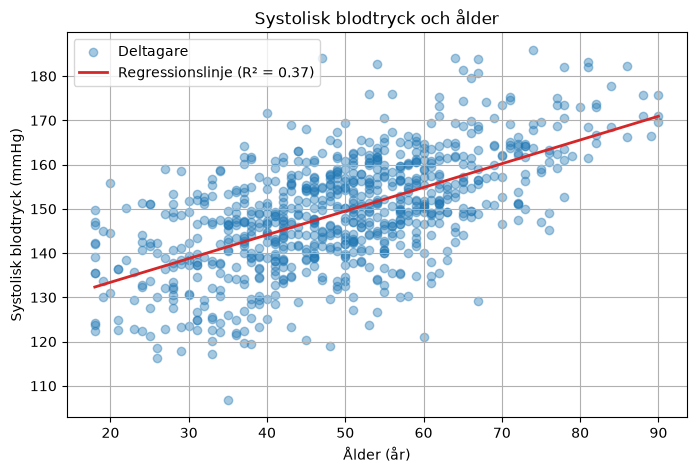

In [20]:
fig, ax = plt.subplots(figsize=(8,5))

ax.scatter(df["age"], df["systolic_bp"], alpha=0.4, label = "Deltagare")

age_line = np.linspace(df["age"].min(), df["age"].max(), 100)
bp_line = coefs["intercept"] + coefs["age"] * age_line
ax.plot(age_line, bp_line, color="tab:red", linewidth=2, label=f"Regressionslinje (R² = {r2:.2f})")
ax.set_title("Systolisk blodtryck och ålder")
ax.set_xlabel("Ålder (år)")
ax.set_ylabel("Systolisk blodtryck (mmHg)")
ax.grid(True)
ax.legend()
plt.show()


##### Tolkning av regressionen

Regressionen visar ett positivt samband mellan ålder och systoliskt blodtryck: blodtrycket ökar med åldern.

**Lutningen** är 0,54 mmHg per år. Det betyder att blodtrycket i genomsnitt ökar med cirka 5,4 mmHg för varje tioårsperiod.

**R² är 0,37.** Åldern förklarar alltså cirka 37 % av variationen i blodtrycket. Det är ett måttligt samband. Resten av variationen, cirka 63 %, beror på andra faktorer, till exempel vikt, kön eller livsstil, och på slumpmässig variation mellan personer. Det syns i grafen, där punkterna ligger utspridda runt linjen.

**Interceptet** (122,68 mmHg) är det förutsagda blodtrycket vid 0 års ålder. Det saknar praktisk betydelse eftersom den yngsta deltagaren är 18 år, men det behövs för att placera linjen rätt.

#### Ny analys: sjukdomsförekomst per rökstatus och kön

I Del 1 analyserades bara den totala andelen med sjukdomen. Här undersöker jag om andelen skiljer sig mellan rökare och icke-rökare, och mellan män och kvinnor. Eftersom disease är en ja/nej-variabel (0/1) jämför jag andelar med ett z-test för två andelar.

In [21]:
analyzer.rate_by_group("smoker")

,antal,andel
smoker,,
No,587,0.048
Yes,213,0.089


In [22]:
analyzer.rate_by_group("sex")

,antal,andel
sex,,
F,403,0.045
M,397,0.073


In [23]:
analyzer.rate_by_group(["sex","smoker"])

antal  andel
sex smoker              
F   No        287  0.035
    Yes       116  0.069
M   No        300  0.060
    Yes        97  0.113

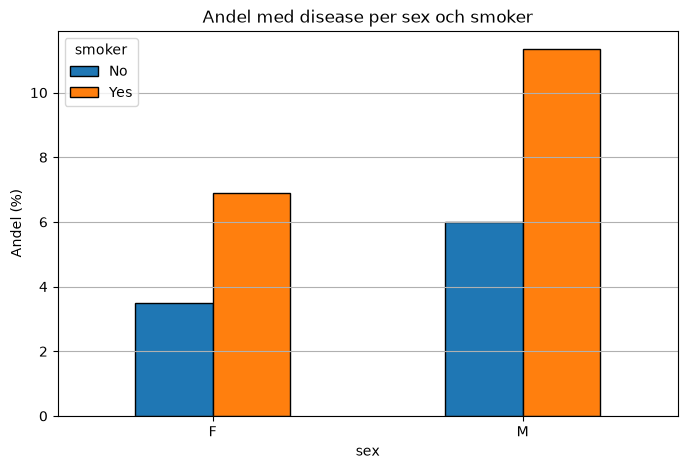

In [24]:
analyzer.plot_rate_by_group("sex", "smoker")
plt.show()

In [25]:
result_smoke_disease = analyzer.compare_rates("smoker", "Yes", "No")
result_sex_disease = analyzer.compare_rates("sex", "M", "F")
pd.DataFrame([result_smoke_disease, result_sex_disease],
             index = ["Rökare vs icke-rökare", "Män vs kvinnor"]).round(4)

,andel_grupp1,andel_grupp2,skillnad,z,p
Rökare vs icke-rökare,0.0892,0.0477,0.0415,2.2063,0.0274
Män vs kvinnor,0.0730,0.0447,0.0284,1.7069,0.0878


##### Tolkning av sjukdomsförekomsten

Grafen visar andelen med sjukdomen bland rökare och icke-rökare, uppdelat på män och kvinnor. Manliga rökare har högst andel sjuka (11,3 %), medan kvinnliga icke-rökare har lägst andel (3,5 %). Rökare har en högre andel sjuka än icke-rökare hos både män och kvinnor.

Skillnaden mellan rökare (8,9 %) och icke-rökare (4,8 %) är statistiskt signifikant, eftersom p-värdet (0,027) är mindre än 0,05.

Skillnaden mellan män (7,3 %) och kvinnor (4,5 %) är däremot inte signifikant, eftersom p-värdet (0,088) är större än 0,05.

Det är intressant att rökning inte hade någon signifikant effekt på blodtrycket i Del 1 (p = 0,33), men däremot på sjukdomen. Det kan tyda på att rökning påverkar sjukdomen på något annat sätt än via blodtrycket.

En begränsning är att bara 47 personer har sjukdomen, och vissa grupper är mycket små, till exempel bara 8 sjuka kvinnliga rökare. Därför är resultaten osäkra.

Sammanfattningsvis finns det ett tydligt samband mellan rökning och sjukdomen. Eftersom detta är observationsdata visar analysen dock inte att rökning orsakar sjukdomen, eftersom andra faktorer också kan spela in.